# Deep Learning – Rendu 1 : CNN sur EuroSAT  

## Rendu le 21/12

**Auteur :** *BESSADET Theo* — **UE :** Deep Learning — **Deadline envisagée :** 13 décembre
**Données :** EuroSAT (torchvision) — occupation des sols en imagerie satellite, 10 classes, images 64×64×3.

## Consignes

- **Baseline** : un CNN dont l'architecture est 100 % maîtrisée (comme dans les premiers TP).
- **Réseaux pré-entraînés** : au moins un modèle classique (type ImageNet), idéalement deux pour comparer. Le transfert doit être fait par moi-même.
- **Stratégies d'apprentissage** : comparer au moins deux techniques, modèle complètement gelé vs fine-tuning (total ou partiel).
- **Taille de l'échantillon d'apprentissage** *(optionnel)* : comparer les performances selon la taille du jeu d'entraînement, jusqu'à 1 % des données.
- **Probing / sondage** : ajouter des hooks et brancher des sondes pour savoir où est encodée quelle information.
- **Analyses** : des zones de texte pour commenter les résultats.
- **Interprétabilité** : montrer quelque chose sur la décision, avec de la saillance ou du CAM.
- **Option** : comparer avec des modèles pré-entraînés sur les données cibles (HuggingFace).
- **Évaluation** : notebook + discussion rapide en séance de TP.

## Plan

1. **X Données et préparation** : chargement d'EuroSAT_MS, split train/val/test, normalisation, visualisation de quelques exemples.
2. **X CNN fait maison (baseline)** : architecture codée à la main, entraînement, courbes, résultats.
3. **X CNN construit avec les modules PyTorch** : *(même architecture réécrite avec `nn.Module` / `nn.Sequential`)*, entraînement et comparaison avec la baseline.
4. **X Fine-tuning d'un modèle CNN pré-entraîné** : *ResNet18*
   - X modèle gelé (extraction de caractéristiques) : modification couche d'entrée pour accepter 13 canaux, couches sortie pour donner 10 logits;
   - fine-tuning partiel (quelle partie ?) ;
   - X fine-tuning complet : importer l'architecture avec initialisation aléatoire des poids - entrainement end-to-end.
5. **X L-TAE** (article vu récemment) : Reprise de l'architecture, avec adaptation de l'encodeur (attention spectrale et non temporelle)
6. **X Visualisation des performances** : visualisation courbes loss/accuracy des modeles lors apprentissage. Comparaison metriques en validation
7. **Comparaison selon la taille du jeu d'entraînement** *(optionnel)* : 1 %, 10 %, 100 %.
8. **Probing** : hooks sur les couches intermédiaires et sondes.
9. **Interprétabilité** : saillance ou Grad-CAM.
10. **Conclusion** : tableau récapitulatif et discussion.


## 1. Données et préparation

- **Chargement** : `torchvision.datasets.EuroSAT` (27 000 images RGB 64×64, 10 classes), téléchargé dans `data/`. Les images sont converties en tenseurs `(N, 3, 64, 64)` dans [0, 1] puis toutes chargées sur le GPU (≈ 1,3 Go en float32) pour éviter les allers-retours CPU/GPU.
- **Split stratifié** (classes légèrement déséquilibrées, 2 000 à 3 000 images par classe) : 20 % test, puis 10 % du reste en validation → ≈ 19 400 / 2 200 / 5 400 images. Le **test est mis de côté** jusqu'à l'évaluation finale ; la validation sert à l'early stopping.
- **Normalisation par canal** : moyenne et écart-type calculés **sur le train uniquement** (pas de fuite vers val/test), puis appliqués aux trois jeux.

In [ ]:
%load_ext autoreload
%autoreload 2

import gc
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from models.CNN_Pytorch import CNN_torch
from models.CNN_scratch import CNN_scratch, evaluer_scratch, fit_scratch
from models.training import (
    mlflow_load,
    probas,
)
from models.Transformers_LTAE_like import SpectralLTAE
from sklearn.model_selection import train_test_split
from torch import nn
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import inspect
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import tifffile
import torch
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("sqlite:///" + Path("mlflow.db").resolve().as_posix())
mlflow.set_experiment("EuroSAT_MS")
print("device :", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device : cuda | NVIDIA GeForce RTX 5070 Ti


In [2]:
# ======================
# CONFIGURATION MATÉRIEL
# ======================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} (VRAM: {torch.cuda.get_device_properties(device).total_memory / 1024**3:.1f} Go)" if device.type == "cuda" else f"Device: {device}")

# ======================
# DATASET EUROSAT_MS
# ======================
class EuroSATMSDataset:
    def __init__(self, root_dir="data/EuroSAT_MS"):
        self.root_dir = root_dir
        self.samples = []
        self.class_to_idx = {}

        # Cas 1: Structure avec sous-dossiers par classe
        subdirs = [d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))]
        if subdirs:
            self.classes = sorted(subdirs)
            self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
            for cls in self.classes:
                cls_dir = os.path.join(root_dir, cls)
                for fname in sorted(os.listdir(cls_dir)):
                    if fname.endswith('.tif'):
                        self.samples.append((os.path.join(cls_dir, fname), self.class_to_idx[cls]))
        # Cas 2: Tout dans un dossier, classe dans le nom (AnnualCrop_1.tif)
        else:
            all_files = [f for f in os.listdir(root_dir) if f.endswith('.tif')]
            self.classes = sorted({f.split('_')[0] for f in all_files})
            self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
            for fname in sorted(all_files):
                cls = fname.split('_')[0]
                self.samples.append((os.path.join(root_dir, fname), self.class_to_idx[cls]))

        if not self.samples:
            raise ValueError(f"Aucun fichier .tif trouvé dans {root_dir}")

# ======================
# CHARGEMENT OPTIMISÉ (16 threads pour Ryzen 7 7800X3D)
# ======================
def load_tif(path):
    """Charge une image TIFF et la convertit en tenseur (C, H, W) float32"""
    img = tifffile.imread(path) # (64, 64, 13)
    img = img.transpose(2,0,1)
    return torch.from_numpy(img.astype(np.float32))

# Initialisation
dataset = EuroSATMSDataset()
file_paths = [s[0] for s in dataset.samples]
labels = [s[1] for s in dataset.samples]
classes_ms = dataset.classes

print(f"\nChargement de {len(file_paths)} images avec {os.cpu_count()} threads (Ryzen 7 7800X3D)...")

# Chargement PARALLÈLE (utilise tous les threads CPU)
with ThreadPoolExecutor(max_workers=os.cpu_count()) as executor:
    X_ms = torch.stack(list(tqdm(executor.map(load_tif, file_paths), total=len(file_paths), desc="Chargement MS")))


y_ms = torch.tensor(labels, dtype=torch.long)
ram_used = X_ms.element_size() * X_ms.nelement() / 1024**3
print(f"X_ms shape: {X_ms.shape} | RAM utilisée: {ram_used:.1f} Go / 32 Go")

# ======================
# SPLIT STRATIFIÉ
# ======================
idx = np.arange(len(y_ms))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42, stratify=y_ms.numpy())
idx_train, idx_val = train_test_split(idx_train, test_size=0.1, random_state=42, stratify=y_ms[idx_train].numpy())

# ======================
# NORMALISATION (sur GPU)
# ======================
X1_brut = X_ms[idx_train[0]].clone()    # on garde une image pour l'afficher
X_ms = X_ms.to(device).div_(65535.)  # uint16 -> [0, 1]
y_ms = y_ms.to(device)
idx_train, idx_val, idx_test = (torch.tensor(i, device=device) for i in (idx_train, idx_val, idx_test))

mean_ms = X_ms[idx_train].mean(dim=(0, 2, 3), keepdim=True)   # (1, 13, 1, 1)
std_ms = X_ms[idx_train].std(dim=(0, 2, 3), keepdim=True)
X_ms.sub_(mean_ms).div_(std_ms)  # Normalisation en place

# ======================
# CRÉATION DES SPLITS FINAUX
# ======================
X_train_ms, y_train_ms = X_ms[idx_train], y_ms[idx_train]
X_val_ms,   y_val_ms   = X_ms[idx_val],   y_ms[idx_val]
X_test_ms,  y_test_ms  = X_ms[idx_test].to("cpu"),  y_ms[idx_test].to("cpu")
del X_ms  # Libération mémoire

# ======================
# AFFICHAGE FINAL
# ======================
print("\n=== EuroSAT_MS Chargé ===")
print(f"X_train_ms: {X_train_ms.shape} (device: {X_train_ms.device})")
print(f"X_val_ms:   {X_val_ms.shape} (device: {X_val_ms.device})")
print(f"X_test_ms:  {X_test_ms.shape} (device: {X_test_ms.device})")
print(f"Classes:    {classes_ms}")
print(f"Total RAM utilisée: ~{ram_used * 1.3:.1f} Go (32 Go disponibles)")

base = torch.cuda.memory_allocated()      # images seules
print(round(base * 1e-9,2), "Go chargés")

Device: cuda (VRAM: 15.9 Go)

Chargement de 27000 images avec 16 threads (Ryzen 7 7800X3D)...


Chargement MS:   0%|          | 0/27000 [00:00<?, ?it/s]

X_ms shape: torch.Size([27000, 13, 64, 64]) | RAM utilisée: 5.4 Go / 32 Go

=== EuroSAT_MS Chargé ===
X_train_ms: torch.Size([19440, 13, 64, 64]) (device: cuda:0)
X_val_ms:   torch.Size([2160, 13, 64, 64]) (device: cuda:0)
X_test_ms:  torch.Size([5400, 13, 64, 64]) (device: cpu)
Classes:    ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Total RAM utilisée: ~7.0 Go (32 Go disponibles)
4.6 Go chargés


In [ ]:
# ======================
# AFFICHAGE : 13 BANDES (brut vs normalisé) + COMPOSITIONS COLORÉES
# ======================
img_raw  = X1_brut.cpu()          # (13, 64, 64) brute, copiée avant normalisation
img_norm = X_train_ms[0].cpu()    # (13, 64, 64) normalisée

band_names = ["B1 coastal", "B2 blue", "B3 green", "B4 red", "B5 RE1", "B6 RE2",
              "B7 RE3", "B8 NIR", "B8A RE4", "B9 WV", "B10 cirrus", "B11 SWIR1", "B12 SWIR2"]

def afficher_bandes(echelle_commune=False):
    """Ligne 1 : brut | ligne 2 : normalisé. Colorbar = min et max réellement utilisés.
    echelle_commune=False : chaque image a sa propre échelle (min-max de la bande)
    echelle_commune=True  : une seule échelle par ligne (toutes bandes comparables)"""
    fig, axes = plt.subplots(2, 13, figsize=(30, 5.5), layout="constrained")
    lignes = [(img_raw, "brut", "{:.0f}"), (img_norm, "norm.", "{:.2f}")]
    for r, (img, label, fmt) in enumerate(lignes):
        vmin, vmax = (img.min().item(), img.max().item()) if echelle_commune else (None, None)
        for c in range(13):
            ax = axes[r, c]
            im = ax.imshow(img[c], cmap="viridis", vmin=vmin, vmax=vmax)   # pas de stretch
            ax.set_title(f"{band_names[c]}\n{label}" if r == 0 else label, fontsize=8)
            ax.axis("off")
            cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03)
            lo, hi = im.get_clim()
            cb.set_ticks([lo, hi])
            cb.set_ticklabels([fmt.format(lo), fmt.format(hi)])
            cb.ax.tick_params(labelsize=7)
    plt.show()

afficher_bandes(echelle_commune=False)   # même rendu visuel, échelles différentes (colorbars)

def afficher_bandes():
    """Ligne 1 : brut | ligne 2 : normalisé.
    Une échelle commune par ligne, avec une seule colorbar à droite de chaque ligne."""
    fig, axes = plt.subplots(2, 13, figsize=(26, 4.5), layout="constrained")
    lignes = [(img_raw, "brut", "{:.0f}"), (img_norm, "norm.", "{:.2f}")]
    for r, (img, label, fmt) in enumerate(lignes):
        vmin, vmax = img.min().item(), img.max().item()          # min/max de toute la ligne
        for c in range(13):
            im = axes[r, c].imshow(img[c], cmap="viridis", vmin=vmin, vmax=vmax)
            axes[r, c].set_title(f"{band_names[c]}\n{label}" if r == 0 else label, fontsize=8)
            axes[r, c].axis("off")
        cb = fig.colorbar(im, ax=axes[r, :].tolist(), location="right", pad=0.01, shrink=0.9)
        cb.set_label(f"valeur {label}", fontsize=9)
    plt.show()

afficher_bandes()

# --- Compositions colorées : MÊME étirement pour les 3 canaux ---
def composite(img, bands, p=(2, 98)):
    rgb = img[list(bands)].permute(1, 2, 0).numpy()               # (64, 64, 3)
    lo, hi = np.percentile(rgb, p)                                # un seul (lo, hi) pour R, G et B
    return np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

composites = [("Couleur vraie (B4,B3,B2)",          (3, 2, 1)),
              ("Fausse couleur végét. (B8,B4,B3)",  (7, 3, 2)),
              ("SWIR (B12,B8,B4)",                  (12, 7, 3))]   # 12 = B12 (et non 11 = B11)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (titre, bands) in zip(axes, composites):
    ax.imshow(composite(img_raw, bands))
    ax.set_title(titre)
    ax.axis("off")
plt.suptitle(f"Image 0 — classe : {classes_ms[y_train_ms[0].item()]}", y=1.02)
plt.tight_layout()
plt.show()

# --- Plages de valeurs brutes vs normalisées ---
print("Plages de valeurs par bande :")
for c in range(13):
    print(f"{band_names[c]:<10} brut [{img_raw[c].min():8.1f}, {img_raw[c].max():8.1f}]   "
          f"norm [{img_norm[c].min():5.2f}, {img_norm[c].max():5.2f}]")

In [ ]:

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(f"Device: {device} (VRAM: {torch.cuda.get_device_properties(device).total_memory / 1024**3:.1f} Go)" if device.type == "cuda" else f"Device: {device}")

# # Chargement : images PIL -> tenseurs (3, 64, 64) dans [0, 1]
# eurosat = datasets.EuroSAT(root="data", download=True, transform=transforms.PILToTensor())   # uint8, (3, 64, 64)
# classes = eurosat.classes

# y = torch.tensor(eurosat.targets, dtype=torch.long)

# loader = DataLoader(eurosat, batch_size=512, shuffle=False, num_workers=max(1, os.cpu_count() // 2))  # shuffle=False : ordre = celui de y
# X = torch.cat([xb for xb, _ in tqdm(loader, desc="Chargement")])    # (27000, 3, 64, 64) uint8

# # Split stratifié sur les indices : test 20 %, puis validation 10 % du reste
# idx = np.arange(len(y))
# idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42, stratify=y.numpy())
# idx_train, idx_val = train_test_split(idx_train, test_size=0.1, random_state=42, stratify=y[idx_train].numpy())

# # Tout sur le device : uint8 -> float32 dans [0, 1], puis normalisation par canal (stats du train uniquement)
# X = X.to(device).float().div_(255.)
# y = y.to(device)
# idx_train, idx_val, idx_test = (torch.tensor(i, device=device) for i in (idx_train, idx_val, idx_test))

# mean = X[idx_train].mean(dim=(0, 2, 3), keepdim=True)   # (1, 3, 1, 1)
# std = X[idx_train].std(dim=(0, 2, 3), keepdim=True)
# X.sub_(mean).div_(std)                                  # en place : évite une copie de 1,3 Go

# X_train, y_train = X[idx_train], y[idx_train]
# X_val,   y_val   = X[idx_val],   y[idx_val]
# X_test,  y_test  = X[idx_test],  y[idx_test]
# del X

# print("X_train :", X_train.shape, "\nX_val :", X_val.shape, "\nX_test :", X_test.shape)
# print("Classes :", classes)

# # ======================
# # AFFICHAGE FINAL
# # ======================
# print("\n=== EuroSAT Chargé ===")
# print(f"X_train: {X_train.shape} (device: {X_train.device})")
# print(f"X_val:   {X_val.shape} (device: {X_val.device})")
# print(f"X_test:  {X_test.shape} (device: {X_test.device})")
# print(f"Classes:    {classes}")

# base = torch.cuda.memory_allocated()      # images seules
# print(round(base * 1e-9,2), "Go chargés")


## 2. CNN fait maison (baseline)

Les couches et la classe `Modele` sont importées depuis `CNN.py` (repris de `CNN.ipynb`).

**Architecture** (inspirée du modèle "large" de MNIST, adaptée à des images 64×64×3) : 3 blocs `Conv 3×3 (same) → ReLu → MaxPool 2×2`, avec un nombre de filtres doublé à chaque pooling (32 → 64 → 128), puis `DropOut(0.3) → Flatten → Dense(128) → ReLu → Dense(10)`.

| Étape | Sortie |
|---|---|
| Entrée | 3 × 64 × 64 |
| Bloc 1 (32 filtres) | 32 × 32 × 32 |
| Bloc 2 (64 filtres) | 64 × 16 × 16 |
| Bloc 3 (128 filtres) | 128 × 8 × 8 |
| Flatten → Dense → Dense | 8 192 → 128 → 10 |

- **Padding `same`** : la taille n'est réduite que par le pooling, ce qui garde une carte 8×8 en sortie des features (utile plus tard pour le Grad-CAM).
- **3 blocs** plutôt que 2 : les images sont plus grandes et plus riches (textures, couleurs) que MNIST.
- **≈ 1,14 M paramètres**, dont ≈ 92 % dans la première Dense : c'est la principale source de sur-apprentissage, d'où le DropOut juste avant.

**Hyperparamètres** : SGD simple (pas de momentum, comme dans `Modele`), `lr = 0.05` (plus faible que sur MNIST car le réseau est plus profond et sans BatchNorm), `batch_size = 128`, 60 epochs maximum, early stopping sur la loss de validation avec `patience = 8`. Ces valeurs sont un point de départ, à ajuster sur la validation (jamais sur le test).

In [ ]:
configs = {
    "base":             (CNN_scratch, {"input_shape":(13,64,64), "batch_size": 128, "lr": 0.04, "patience": 10}),
    "augmentation":     (CNN_scratch, {"input_shape":(13,64,64), "batch_size": 128, "lr": 0.04, "patience": 10, "augment": True}),
    "momentum + decay": (CNN_scratch, {"input_shape":(13,64,64), "batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95}),
    "tout":             (CNN_scratch, {"input_shape":(13,64,64), "batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": True}),
}

modeles_s, perfs_s, temps_s = {}, {}, {}
defauts = {k: v.default for k, v in inspect.signature(CNN_scratch).parameters.items()
           if v.default is not inspect.Parameter.empty}

for nom, (creer, params) in configs.items():
    torch.manual_seed(42)
    modeles_s[nom] = creer(**params)
    perfs_s[nom], temps_s[nom] = mlflow_load(modeles_s[nom], nom, 
                                               X_train_ms, y_train_ms, X_val_ms, y_val_ms, classes_ms, 
                                               strategie='', impl="scratch",
                                               fit=fit_scratch, evaluer=evaluer_scratch, probabilites=probas,
                                               archi=inspect.getsource(CNN_scratch), 
                                               **{**defauts, **params})

def run()

=== base ===
Paramètres : 1,104,266 (entraînables : 1,104,266)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

... (200 outputs left out)

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Batchs:   0%|          | 0/151 [00:00<?, ?it/s]

Early stop at epoch 50
Stop apres 50 epochs : val_loss=0.1086


## 3. CNN construit avec les modules PyTorch

**Même architecture** que la baseline, réécrite avec `nn.Sequential` : `nn.Conv2d(padding='same')`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Dropout`, `nn.Flatten`, `nn.Linear`. La boucle d'entraînement utilise `torch.optim.SGD` et `nn.CrossEntropyLoss` (log-softmax + NLL, comme dans `Modele`).

**Mêmes hyperparamètres** (SGD sans momentum, `lr = 0.05`, `batch_size = 128`, 60 epochs max, `patience = 8` sur la loss de validation, restauration des meilleurs poids) pour que la comparaison porte sur l'implémentation et non sur les réglages.

Seule différence volontairement conservée : l'**initialisation par défaut de PyTorch** (Kaiming uniforme) au lieu de `randn / √(fan_in)`. On pourrait aussi passer à Adam ou ajouter du momentum, mais la comparaison ne serait plus équitable.

In [ ]:
configs_torch = {
    "base": ((lambda: CNN_torch(13)), {"batch_size": 128, "lr": 0.04, "patience": 10}),
    "tout": ((lambda: CNN_torch(13)), {"batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": True}),
}

modeles_t, perfs_t, temps_t = {}, {}, {}
for nom, (creer, params) in configs_torch.items():
    torch.manual_seed(42)
    modeles_t[nom] = creer()
    perfs_t[nom], temps_t[nom] = mlflow_load(modeles_t[nom], nom, X_train_ms, y_train_ms, X_val_ms, y_val_ms, classes_ms, 
                                             strategie='', impl="CNN_Pytorch", **params)
    print(f"{int(temps_t[nom])} secondes")



=== base ===
Paramètres : 1,101,514 (entraînables : 1,101,514)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Early stop at epoch 57
Stop apres 57 epochs : val_loss=0.1354
73 secondes
=== tout ===
Paramètres : 1,101,514 (entraînables : 1,101,514)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Early stop at epoch 51
Stop apres 51 epochs : val_loss=0.0769
71 secondes


## 4. FineTuning
Quel modèle ? Tester un CNN et un transformer style L-TAE ?

Cahier de bord :  
Import du modele resnet
Il faut le passer sur GPU pour accelerer les calculs
le forward de base produit sortie (N, 1000) $\to$ remplace la derniere couche du linéaire (actuellement n $\to$ 1000) par du n $\to$ 10  
**Structure de ResNet18 (simplifiée) :**
- Entrée : 
  - Conv2d (N,3,64,64) $\to$ (N,64,32,32) 
  - BatchNorm2D : Pour le batch actuel, dans chaque canal, `BatchNorm` fait une normalisation centrée réduite des valeurs. En evaluation, on utilise pas $\mu$|$\sigma$ du batch, mais la moyennes mobiles de $\mu$ et $\sigma²$. L'objectif est de garder des activations stables d'une couche à l'autre (converge + vite et accepte lr plus grand), evite explosion/vanishing gradient
  - ReLU : activation non linéaire classique
  - MaxPool2D(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False) : (N,64,32,32) $\to$ (N, 64, 16, 16)
- Layer : 4 suite de 2 block, contenant [conv1, bn1, relu, conv2, bn2]. Avec downsample dans 2, 3 et 4 car l'entrée et la sortie de taille différente, alors qu'on a une connexion résiduelle.
  - Layer 1 : (N, 64, 16, 16) $\to$ (N, 64, 16, 16)
  - Layer 2 : (N, 64, 16, 16) $\to$ (N, 128, 8, 8)
  - Layer 3 : (N, 128, 8, 8) $\to$ (N, 256, 4, 4)
  - Layer 4 : (N, 256, 4, 4) $\to$ (N, 512, 2, 2)
-` AdaptiveAvgPool2d((1, 1))` : On fixe la taille de la sortie, et ca accepte n'importe quel taille d'entrée (permet de faire passer image en entrée taille 64x64, 128x128 ... ) : (N, 512, 2, 2) $\to$ (N, 512, 1, 1)
- fc (full_connected) : couche dense de sortie. Actuellement `fc = Linear(512, 1000)` (adapter aux 1000 classes ImageNet) $\to$ a changer pour 10 sortie

In [73]:
rn18 = resnet18(weights = ResNet18_Weights.DEFAULT).to(device)
for p in rn18.parameters(): 
    p.requires_grad = False
rn18.conv1 = nn.Sequential(nn.Conv2d(13,32,kernel_size=(5,5), padding=(1,1), bias=False).to(device), 
                           nn.Conv2d(32, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False).to(device))
rn18.fc = nn.Linear(in_features=512, out_features=10, bias=True).to(device)

params = {'EPOCH': 60, 'lr': 0.005, 'batch_size': 128, 'patience': 15, 'eps': 1e-4, 'momentum': 0.9, 'lr_decay': 1, 'augment': False, 'freeze': 'rn18'}
perf, t = mlflow_load(rn18, "ResNet18 freeze", X_train_ms, y_train_ms, X_val_ms, y_val_ms, classes_ms, strategie='gelé', impl="ResNet18", **params)
print(f"{t} secondes")


rn18_ft = resnet18().to(device) # Poids initialisés aléatoirement
rn18_ft.conv1 = nn.Sequential(nn.Conv2d(13,32,kernel_size=(5,5), padding=(1,1), bias=False).to(device), 
                           nn.Conv2d(32, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False).to(device))
rn18_ft.fc = nn.Linear(in_features=512, out_features=10, bias=True).to(device)

params = {'EPOCH': 60, 'lr': 0.005, 'batch_size': 128, 'patience': 15, 'eps': 1e-4, 'momentum': 0.9, 'lr_decay': 1, 'augment': False}
perf, t = mlflow_load(rn18_ft, "ResNet18 FineTune", X_train_ms, y_train_ms, X_val_ms, y_val_ms, classes_ms, strategie='FineTune end-to-end', impl="ResNet18", **params)

print(f"{t} secondes")

=== ResNet18 freeze ===
Paramètres : 11,282,986 (entraînables : 115,882)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Early stop at epoch 41
Stop apres 41 epochs : val_loss=0.1654
84.81263756752014 secondes
=== ResNet18 FineTune ===
Paramètres : 11,282,986 (entraînables : 11,282,986)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Early stop at epoch 22
Stop apres 22 epochs : val_loss=0.1724
58.88048553466797 secondes


## 5. Transformers L-TAE Like
La on va tenter de faire fonctionner un L-TAE sur nos données EuroSat  
Principe du L-TAE (Light-TemporalAutoEncoder : https://doi.org/10.1007/978-3-030-65742-0_12) mais en remplacant le coté encodeur temporel par encodeur spectral  
On aurait donc :
- nos entrées X : (B, 13, 64, 64)
- Encodeur : (B, 13, 64, 64) $\to$ (B, 13, n) avec n choisit
  - Petit CNN à 1 canal d'entré, partagé entre les bandes. On met les bandes dans la dimension batch, on encode, puis on remet les bandes. Ici on partage les poids entre les canaux, ce qui est différenciant est donc la position dans l'image.
- L-TAE : (B, 13, n) $\to$ (B, n)
  - La on va encoder la repartition dans le spectre avec un S. [443, ... , 2190] nm dans EuroSat_MS. Pour reutiliser le calcul de l'article, si on fait /10 => [44, ..., 219] on retombe sur le même ordre de grandeur que les jours de l'année (365) ; on va donc pouvoir utilise $\tau = 1000$ 
- MLP : (B, n) $\to$ (B, 10)
  - Le classifieur qui sort des logits

![alt text](data/schema_archi.jpeg)

Modele BandEncoder

In [14]:
specLTAE_Band = SpectralLTAE(encoder="band").to(device)
print(round((torch.cuda.memory_allocated() - base) / 1e6,4), "Mo du model")

print(X_train_ms.shape, X_val_ms.shape, y_train_ms.shape, y_val_ms.shape)
params = {"EPOCH": 60, "batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": False}
perf_fit, temps = mlflow_load(specLTAE_Band, "L-TAE Like Band", X_train_ms, y_train_ms, X_val_ms, y_val_ms, classes_ms, "L-TAE", **params)

specLTAE_Band.to("cpu")
gc.collect(); torch.cuda.empty_cache()
print(round((torch.cuda.memory_allocated() - base) / 1e6,4), "Mo en trop")

196.3771 Mo du model
torch.Size([19440, 13, 64, 64]) torch.Size([2160, 13, 64, 64]) torch.Size([19440]) torch.Size([2160])
=== L-TAE Like Band ===
Paramètres : 128,106 (entraînables : 128,106)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Stop apres 60 epochs : val_loss=0.0858
191.317 Mo en trop


Modele CanalEncoder

In [15]:
specLTAE_Canal = SpectralLTAE(encoder="canal").to(device)
print(round((torch.cuda.memory_allocated() - base) / 1e6,4), "Mo du model")

print(X_train_ms.shape, X_val_ms.shape, y_train_ms.shape, y_val_ms.shape)
params = {"EPOCH": 60, "batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": False}
perf_fit, temps = mlflow_load(specLTAE_Canal, "L-TAE Like Canal", 
                              X_train_ms, y_train_ms, X_val_ms, y_val_ms, classes_ms, "L-TAE", **params)

specLTAE_Canal.to("cpu")
gc.collect(); torch.cuda.empty_cache()
print(round((torch.cuda.memory_allocated() - base) / 1e6,4), "Mo en trop")

196.3187 Mo du model
torch.Size([19440, 13, 64, 64]) torch.Size([2160, 13, 64, 64]) torch.Size([19440]) torch.Size([2160])
=== L-TAE Like Canal ===
Paramètres : 1,242,858 (entraînables : 1,242,858)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Early stop at epoch 60
Stop apres 60 epochs : val_loss=0.0833
191.317 Mo en trop


Liberer le memoire

In [ ]:
def test_batch(model, x, y, batch_size):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    opt = torch.optim.SGD(model.parameters(), lr=0.02, momentum=0.9)
    crit = nn.CrossEntropyLoss()
    opt.zero_grad(set_to_none=True)
    loss = crit(model(x[:batch_size]), y[:batch_size])
    loss.backward()
    opt.step()
    torch.cuda.synchronize()
    print(f"batch {batch_size:>4} : pic {torch.cuda.max_memory_allocated()/1024**3:.1f} Go")

for bs in (64, 128, 256, 512):
    test_batch(specLTAE_Canal, X_train_ms, y_train_ms, bs)

## 6. Comparaison des implémentations

Les deux modèles étant **figés** (aucun choix ne sera fait à partir de ces chiffres), on peut les évaluer sur le **jeu de test** : c'est l'évaluation finale.

- **Métriques** : loss (cross-entropy), accuracy et **F1 macro** (moyenne non pondérée des F1 par classe, adaptée au léger déséquilibre des classes).
- **Coût** : nombre de paramètres, nombre d'epochs avant l'early stopping et temps d'entraînement (la version PyTorch utilise les convolutions optimisées cuDNN, la version maison passe par `unfold` + `einsum`).
- **Graphique** : courbes de loss train / validation des deux modèles, pour comparer la vitesse de convergence et le sur-apprentissage.

In [90]:
client = MlflowClient()
df = mlflow.search_runs(experiment_names=["EuroSAT_MS"])
df = df[df["status"] == "FINISHED"]          # ignore les runs plantées ou interrompues

derniers = (
    df.sort_values("start_time", ascending=False)
      .drop_duplicates("tags.mlflow.runName", keep="first")   # garde la plus récente par nom
      .sort_values("tags.mlflow.runName")
      .set_index("tags.mlflow.runName")
)
# print(derniers[["run_id", "start_time", "metrics.val_OA"]])


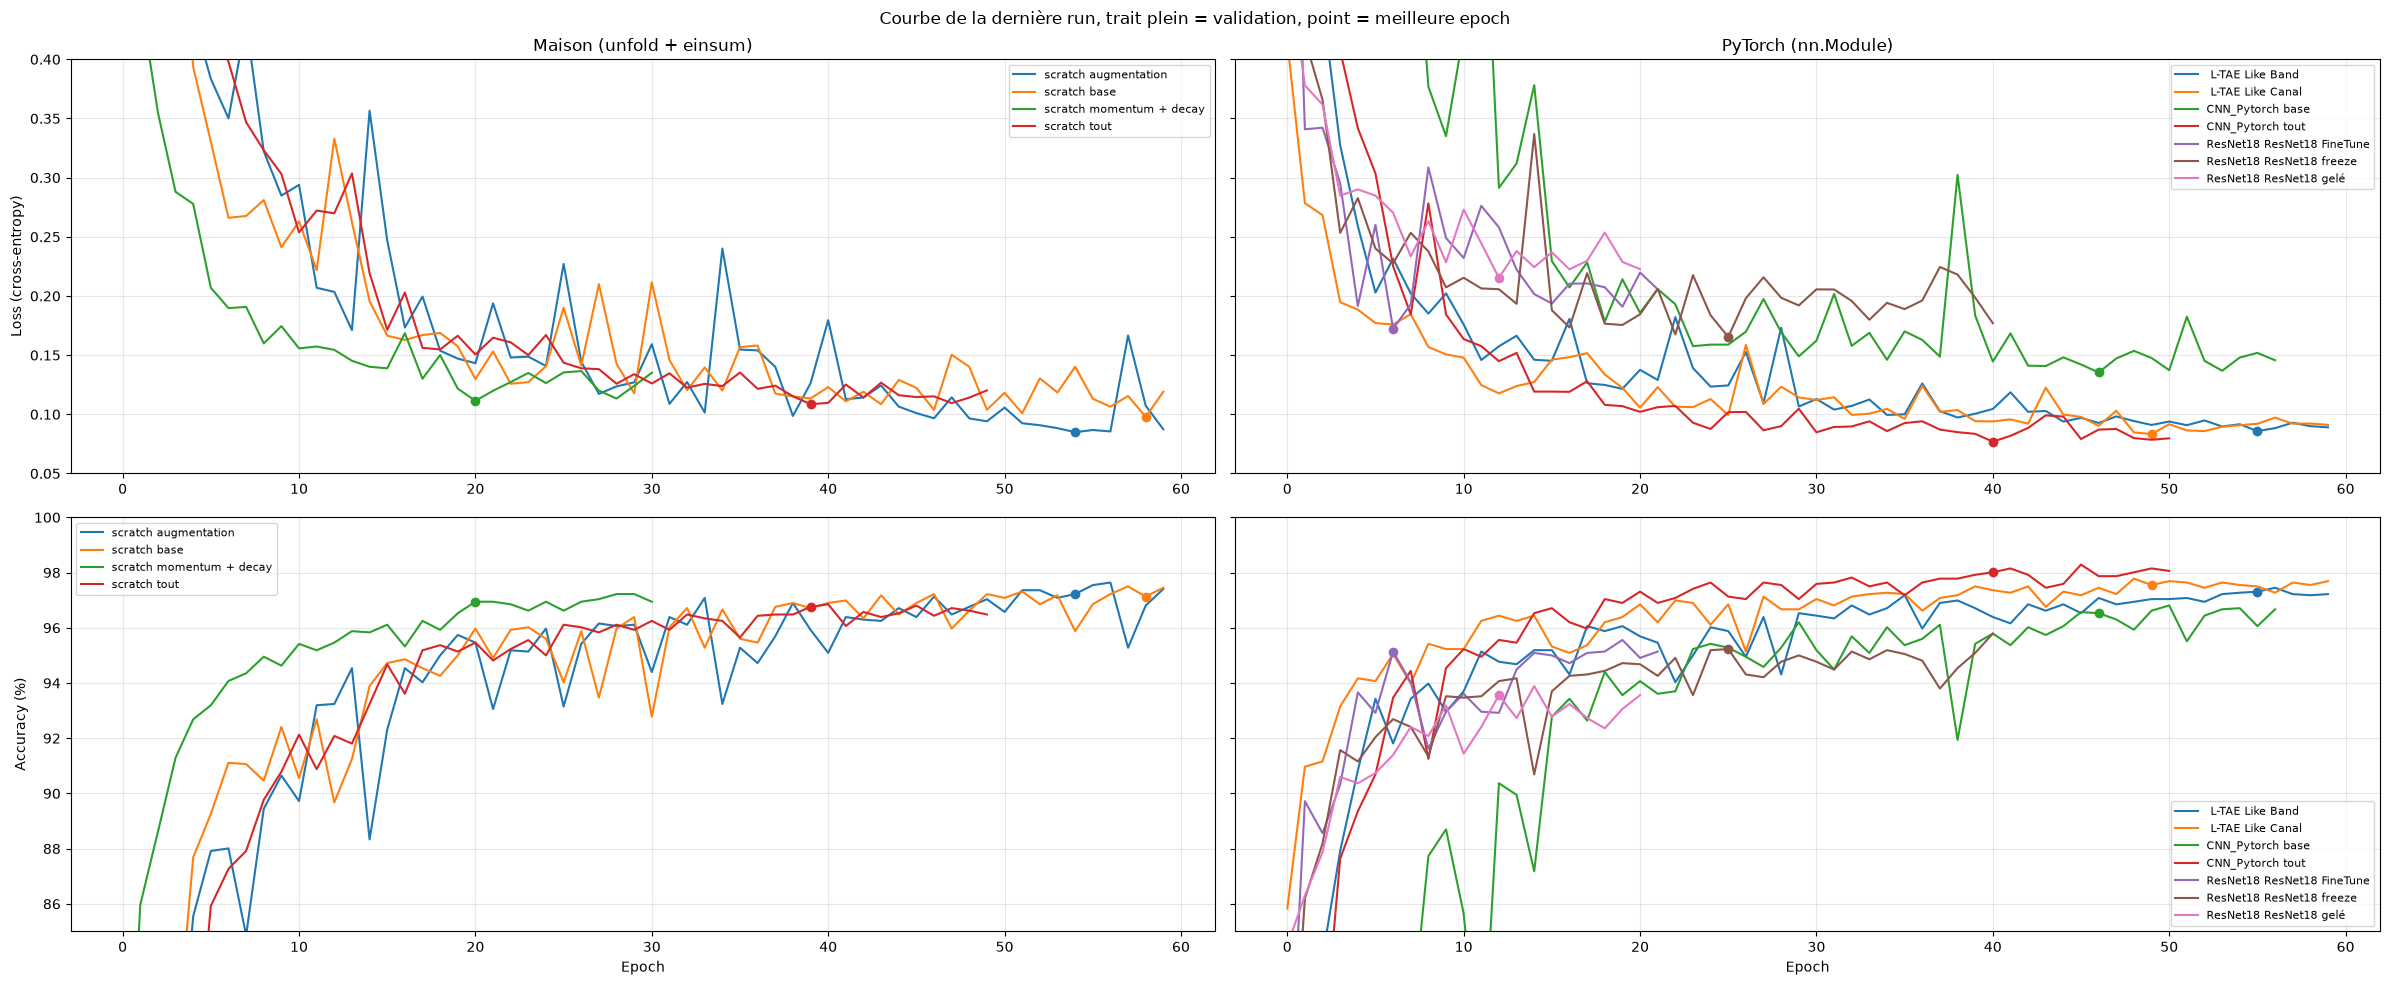

In [95]:
def charger_perf(run_id):
    """Reconstruit le tableau perf_fit : colonnes train_loss, train_acc, val_loss, val_acc."""
    cols = ["train_loss", "train_acc", "val_loss", "val_acc"]
    series = []
    for c in cols:
        hist = sorted(client.get_metric_history(run_id, c), key=lambda m: m.step)
        series.append([m.value for m in hist])
    return np.array(series).T                  # (n_epochs, 4)

perfs = {nom: charger_perf(rid) for nom, rid in derniers["run_id"].items()}

groupes = {
    "Maison (unfold + einsum)": {n: p for n, p in perfs.items() if n.startswith("scratch")},
    "PyTorch (nn.Module)":      {n: p for n, p in perfs.items() if not n.startswith("scratch")},
}

fig, axes = plt.subplots(2, len(groupes), figsize=(12 * len(groupes), 10), sharey="row", squeeze=False)
for j, (titre, runs) in enumerate(groupes.items()):
    for i, (nom, perf) in enumerate(runs.items()):
        best = perf[:, 2].argmin()
        couleur = f"C{i}"
        axes[0, j].plot(perf[:, 2], color=couleur, label=nom)
        axes[0, j].plot(best, perf[best, 2], "o", color=couleur)
        axes[1, j].plot(perf[:, 3] * 100, color=couleur, label=nom)
        axes[1, j].plot(best, perf[best, 3] * 100, "o", color=couleur)
    axes[0, j].set_title(titre)
    axes[1, j].set_xlabel("Epoch")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
axes[0, 0].set_ylabel("Loss (cross-entropy)")
axes[0, 0].set_ylim(0.05,0.4)
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].set_ylim(85,100)
fig.suptitle("Courbe de la dernière run, trait plein = validation, point = meilleure epoch")
plt.tight_layout()
plt.savefig("data/resume_vs_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

In [84]:
N_RUNS = 5
df = mlflow.search_runs(experiment_names=["EuroSAT_MS"])
df = df[df["status"] == "FINISHED"].copy()
df["nom"] = df["tags.mlflow.runName"]

derniers = (df.sort_values("start_time", ascending=False)
              .groupby("nom").head(N_RUNS))          # jusqu'à 5 runs par nom (moins s'il y en a moins)

n_runs = derniers.groupby("nom").size()
print(n_runs)

nom
 L-TAE Like Band              1
 L-TAE Like Canal             1
CNN_Pytorch base              2
CNN_Pytorch tout              2
ResNet18 ResNet18 FineTune    2
ResNet18 ResNet18 freeze      3
ResNet18 ResNet18 gelé        1
scratch augmentation          2
scratch base                  2
scratch momentum + decay      2
scratch tout                  2
dtype: int64


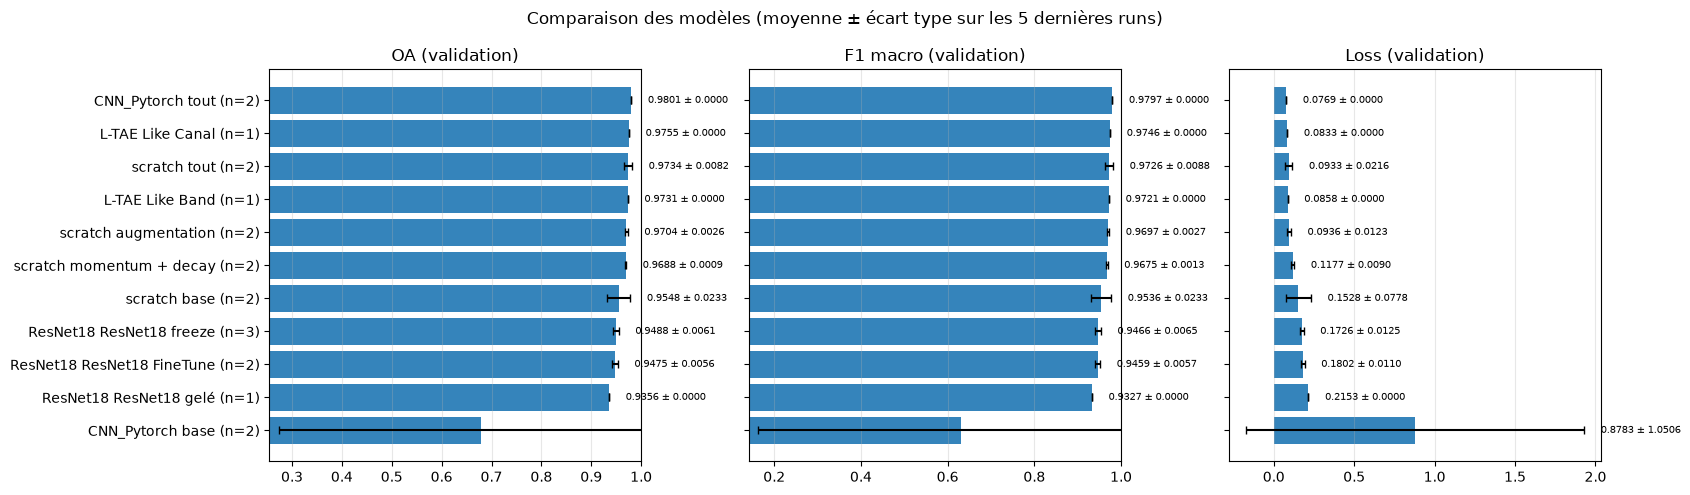

In [85]:
metriques = {
    "metrics.val_OA":        "OA (validation)",
    "metrics.val_f1_macro":  "F1 macro (validation)",
    "metrics.best_val_loss": "Loss (validation)",
}
cols = list(metriques)

moy = derniers.groupby("nom")[cols].mean()
std = derniers.groupby("nom")[cols].std(ddof=1).fillna(0)     # 1 seule run -> NaN -> 0

# Le nombre de runs retenues est affiché dans le label
labels = {nom: f"{nom} (n={n_runs[nom]})" for nom in moy.index}
moy.index = moy.index.map(labels)
std.index = std.index.map(labels)

ordre = moy["metrics.val_OA"].sort_values().index             # le meilleur en haut
moy, std = moy.loc[ordre], std.loc[ordre]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (col, titre) in zip(axes, metriques.items()):
    barres = ax.barh(moy.index, moy[col], xerr=std[col], color="C0", capsize=3, alpha=0.9)
    ax.bar_label(barres, labels=[f"{m:.4f} ± {s:.4f}" for m, s in zip(moy[col], std[col])],
                 padding=12, fontsize=7)
    if "loss" not in col:                      # zoom sur la zone utile pour OA / F1
        ax.set_xlim((moy[col] - std[col]).min() - 0.02, 1.0)
    ax.set_title(titre)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle(f"Comparaison des modèles (moyenne ± écart type sur les {N_RUNS} dernières runs)")
plt.tight_layout()
plt.savefig("data/barres_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

['classe', 'loss', 'accuracy', 'F1', 'ROC AUC', 'average precision']


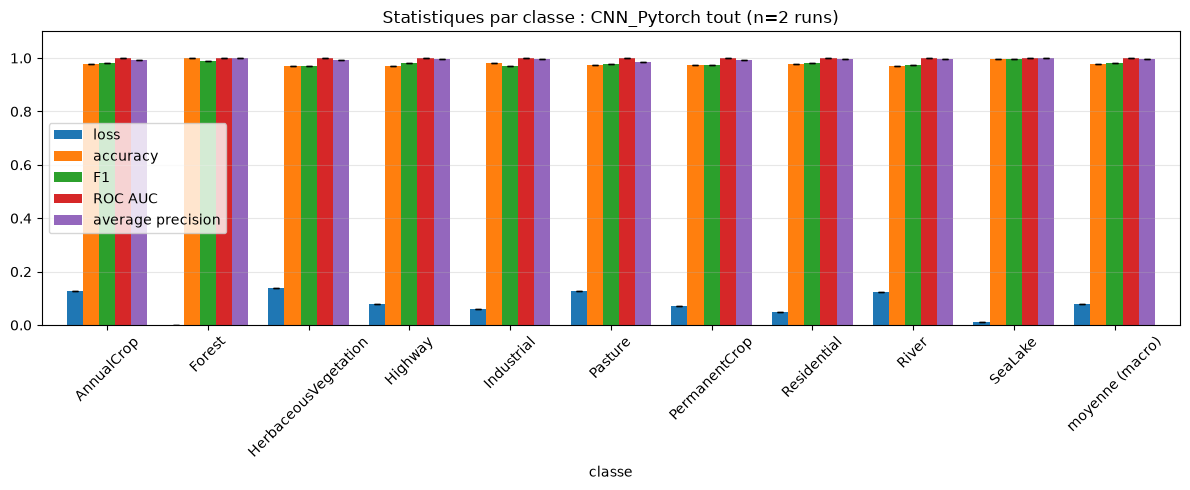

In [86]:
best_model = moy["metrics.best_val_loss"].idxmin()            # meilleure loss de validation moyenne
best_nom = best_model.rsplit(" (n=", 1)[0]
ids = derniers.loc[derniers["nom"] == best_nom, "run_id"].tolist()

stats = mlflow.load_table("stats_par_classe_val.json", run_ids=ids)
print(stats.columns.tolist())                                  # pour vérifier les noms de colonnes

cols_cl = [c for c in stats.select_dtypes("number").columns
           if c.lower() not in ("support", "n", "effectif")]

g = stats.groupby("classe")[cols_cl]
moy_cl, std_cl = g.mean(), g.std(ddof=1).fillna(0)

ax = moy_cl.plot.bar(yerr=std_cl, capsize=2, figsize=(12, 5), rot=45, width=0.8)
ax.set_ylim(max(0, (moy_cl - std_cl).min().min() - 0.03), 1.1)
ax.set_title(f"Statistiques par classe : {best_nom} (n={len(ids)} runs)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("data/barres_classes_best_model.png", dpi=150, bbox_inches="tight")
plt.show()

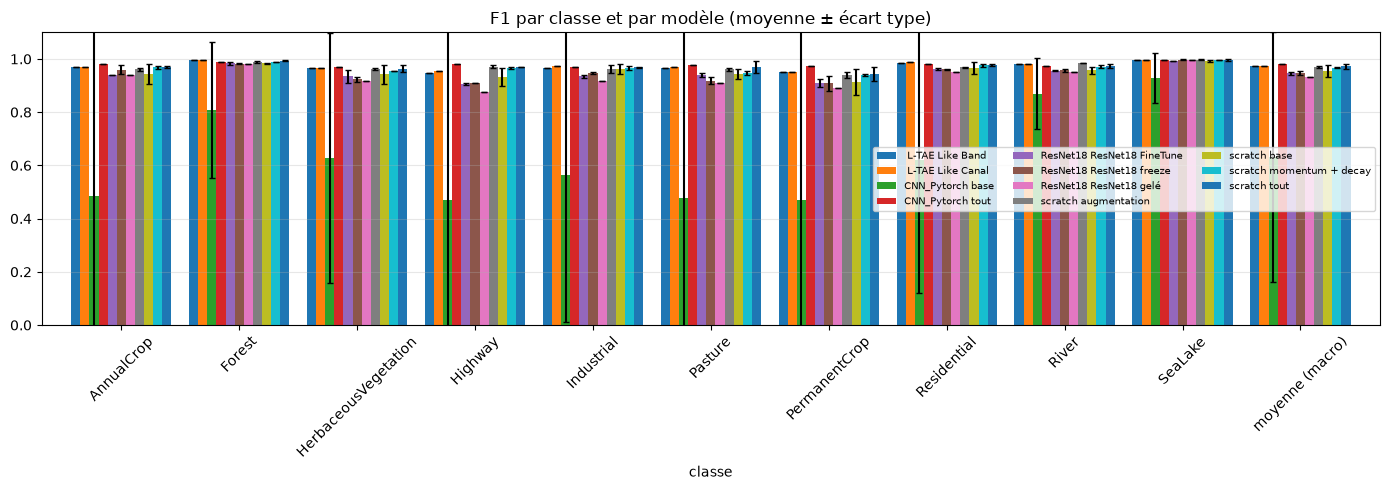

In [87]:
metrique = "F1"        # à remplacer par le nom exact d'une colonne affichée par le print ci-dessus

tables = mlflow.load_table("stats_par_classe_val.json",
                           run_ids=derniers["run_id"].tolist(),
                           extra_columns=["run_id"])
tables["modele"] = tables["run_id"].map(derniers.set_index("run_id")["nom"])

g = tables.groupby(["classe", "modele"])[metrique]
piv_moy = g.mean().unstack("modele")
piv_std = g.std(ddof=1).fillna(0).unstack("modele")

ax = piv_moy.plot.bar(yerr=piv_std, capsize=2, figsize=(14, 5), rot=45, width=0.85)
ax.set_ylim(max(0, (piv_moy - piv_std).min().min() - 0.03), 1.1)
ax.set_title(f"{metrique} par classe et par modèle (moyenne ± écart type)")
ax.legend(fontsize=7, ncol=3)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

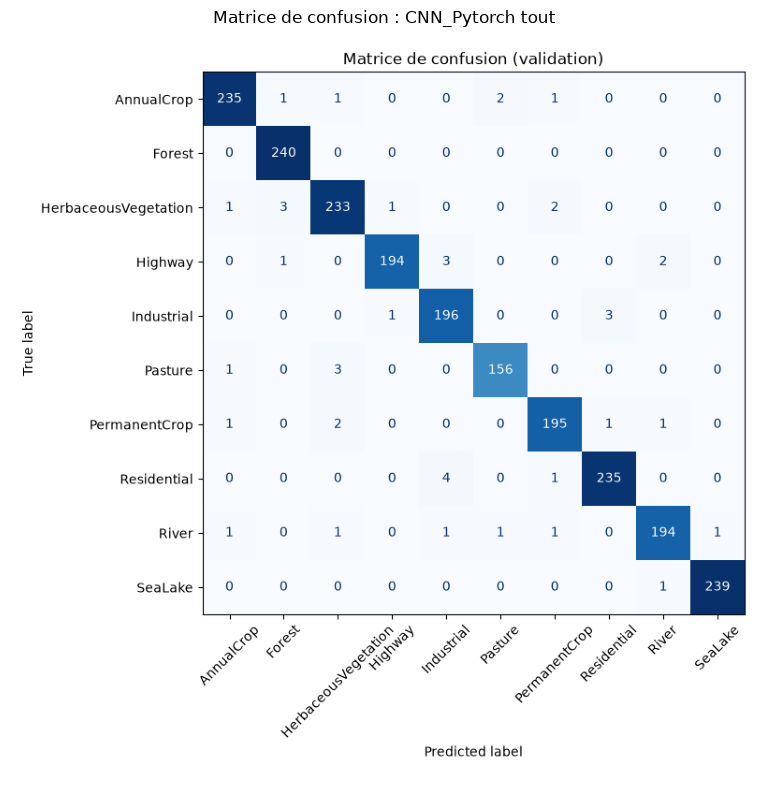

In [88]:
# Meilleure run du meilleur modèle (plus petite loss de validation)
runs_best = derniers[derniers["nom"] == best_nom]
run_id = runs_best.loc[runs_best["metrics.best_val_loss"].idxmin(), "run_id"]

chemin = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="matrice_confusion_val.png")

plt.figure(figsize=(8, 8))
plt.imshow(plt.imread(chemin))
plt.axis("off")
plt.title(f"Matrice de confusion : {best_nom}")
plt.tight_layout()
plt.savefig("data/matrice_confusion_best_model.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Importances données d'entrainement
On va reprendre le meilleur modèle, le CNN, et un transformers pour voir l'influence d'une reduction du jeu de données (jeu de validation fixe)

In [104]:
for pct_keep in [100, 50, 10, 1]:    # Fraction des données train enlevées
    torch.manual_seed(42)

    CNN_train_size = CNN_torch(13)
    specLTAE_Canal_train_size = SpectralLTAE(encoder="canal").to(device)

    n = len(X_train_ms)
    reste = int(n * pct_keep/100)
    print(f'{reste} sur {n}')

    params = {"batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": True}
    perfs_cnn, temps_cnn = mlflow_load(CNN_train_size, "CNN_train_size", X_train_ms[:reste], y_train_ms[:reste], X_val_ms, y_val_ms, classes_ms, 
                                                 strategie=f'{pct_keep}% ({reste} sur {n})', impl="CNN_Pytorch", **params)
    print(f"{int(temps_cnn)} secondes")

    params = {"EPOCH": 60, "batch_size": 128, "lr": 0.02, "patience": 10, "momentum": 0.9, "lr_decay": 0.95, "augment": False}
    perfs_t, temps_t = mlflow_load(specLTAE_Canal_train_size, "specLTAE_Canal_train_size", 
                              X_train_ms[:reste], y_train_ms[:reste], X_val_ms, y_val_ms, classes_ms, strategie=f'{pct_keep}% ({reste} sur {n})', impl="L-TAE", **params)
    print(f"{int(temps_t[nom])} secondes")

19440 sur 19440
=== CNN_train_size ===
Paramètres : 1,101,514 (entraînables : 1,101,514)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

Early stop at epoch 51
Stop apres 51 epochs : val_loss=0.0769
77 secondes
=== specLTAE_Canal_train_size ===
Paramètres : 1,242,858 (entraînables : 1,242,858)


Epochs:   0%|          | 0/60 [00:00<?, ?it/s]

KeyboardInterrupt: 